# **سوال 1-2**

In [ ]:
from google.colab import drive
import os

# اتصال به گوگل درایو
drive.mount('/content/drive')



Mounted at /content/drive


In [ ]:

rar_path = '/content/drive/MyDrive/Copy of CelebFaces_Attributes_8k.rar'
extract_path = '/content/extracted_images'

# ایجاد پوشه برای استخراج
os.makedirs(extract_path, exist_ok=True)

# استخراج فایل rar
!unrar x "{rar_path}" "{extract_path}"

Streaming output truncated to the last 5000 lines.
Extracting  /content/extracted_images/CelebFaces_Attributes_8k/003002.jpg      37%  OK 
Extracting  /content/extracted_images/CelebFaces_Attributes_8k/003003.jpg      37%  OK 
Extracting  /content/extracted_images/CelebFaces_Attributes_8k/003004.jpg      37%  OK 
Extracting  /content/extracted_images/CelebFaces_Attributes_8k/003005.jpg      37%  OK 
Extracting  /content/extracted_images/CelebFaces_Attributes_8k/003006.jpg      37%  OK 
Extracting  /content/extracted_images/CelebFaces_Attributes_8k/003007.jpg      37%  OK 
Extracting  /content/extracted_images/CelebFaces_Attributes_8k/003008.jpg      37%  OK 
Extracting  /content/extracted_images/CelebFaces_Attributes_8k/003009.jpg      37%  OK 
Extracting  /content/extracted_images/CelebFaces_Attributes_8k/003010.jpg      37%  OK 
Extracting  /content/extracted_images/CelebFaces_Attributes_8k/003011.jpg   

In [ ]:
import numpy as np
import cv2
from tqdm import tqdm

def preprocess_images(image_folder, target_size=(64, 64)):
    processed_images = []
    filenames = sorted(os.listdir(image_folder))

    print("Starting Preprocessing...")
    for img_name in tqdm(filenames):
        img_path = os.path.join(image_folder, img_name)

        # خواندن تصویر
        img = cv2.imread(img_path)
        if img is not None:
            # تبدیل BGR به RGB (چون OpenCV تصاویر را BGR می‌خواند)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

            # تغییر سایز به 64x64
            img = cv2.resize(img, target_size)

            # نرمال‌سازی به بازه [0, 1]
            img = img.astype('float32') / 255.0

            processed_images.append(img)

    return np.array(processed_images)

path_final = "/content/extracted_images/CelebFaces_Attributes_8k"
data = preprocess_images(path_final)

print(f"\nFinal data shape: {data.shape}") # باید (8000, 64, 64, 3) باشد

Starting Preprocessing...


100%|██████████| 8000/8000 [00:02<00:00, 2833.54it/s]



Final data shape: (8000, 64, 64, 3)


In [ ]:
import cv2
import os
from tqdm import tqdm

# ۱. ایجاد پوشه خروجی در گوگل درایو (یا حافظه موقت کولب)
output_images_path = '/content/drive/MyDrive/CelebA_Processed_64x64'
os.makedirs(output_images_path, exist_ok=True)

def resize_and_save(input_folder, output_folder, target_size=(64, 64)):
    filenames = sorted(os.listdir(input_folder))

    print(f"Starting to process and save {len(filenames)} images...")

    for img_name in tqdm(filenames):
        img_path = os.path.join(input_folder, img_name)

        # خواندن تصویر
        img = cv2.imread(img_path)

        if img is not None:
            # تغییر سایز (OpenCV به صورت پیش‌فرض از اینترپولیشن Linear استفاده می‌کند که برای Downsampling خوب است)
            res_img = cv2.resize(img, target_size)

            # ذخیره با فرمت JPG در پوشه مقصد
            # نکته: نام فایل همان نام اصلی باقی می‌ماند
            save_path = os.path.join(output_folder, img_name)
            cv2.imwrite(save_path, res_img)

# ۲. فراخوانی تابع
# extract_path همان پوشه‌ای است که فایل rar را در آن unrar کردید
resize_and_save(path_final, output_images_path)

print(f"\nAll images are saved in: {output_images_path}")

Starting to process and save 8000 images...


100%|██████████| 8000/8000 [01:18<00:00, 102.16it/s]


All images are saved in: /content/drive/MyDrive/CelebA_Processed_64x64


# **preprocess**

In [ ]:
!apt-get install unrar


Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
unrar is already the newest version (1:6.1.5-1ubuntu0.1).
0 upgraded, 0 newly installed, 0 to remove and 37 not upgraded.


In [ ]:
import os

# مسیر فایل rar داخل درایو
rar_path = "/content/drive/MyDrive/resized_images.rar"

# پوشه مقصد استخراج
extract_path = "/content/celeba_data"

os.makedirs(extract_path, exist_ok=True)

!unrar x "$rar_path" "$extract_path"


Streaming output truncated to the last 5000 lines.
Extracting  /content/celeba_data/003002.jpg                               37%  OK 
Extracting  /content/celeba_data/003003.jpg                               37%  OK 
Extracting  /content/celeba_data/003004.jpg                               37%  OK 
Extracting  /content/celeba_data/003005.jpg                               37%  OK 
Extracting  /content/celeba_data/003006.jpg                               37%  OK 
Extracting  /content/celeba_data/003007.jpg                               37%  OK 
Extracting  /content/celeba_data/003008.jpg                               37%  OK 
Extracting  /content/celeba_data/003009.jpg                               37%  OK 
Extracting  /content/celeba_data/003010.jpg                               37%  OK 
Extracting  /content/celeba_data/003011.jpg                               37%  OK 
Extracting  /content/celeba_d

In [ ]:
import os

image_files = [f for f in os.listdir(extract_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
print("Actual number of images in folder:", len(image_files))


Actual number of images in folder: 8000


In [ ]:
import os
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import transforms

# preprocessing که قبلاً گفتیم
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))
])

class CelebADataset(Dataset):

    def __init__(self, root_dir, transform=None):

        self.root_dir = root_dir
        self.transform = transform

        self.image_paths = []

        for file in os.listdir(root_dir):

            if file.lower().endswith(('.jpg','.jpeg','.png')):
                self.image_paths.append(
                    os.path.join(root_dir, file)
                )

    def __len__(self):

        return len(self.image_paths)

    def __getitem__(self, idx):

        img_path = self.image_paths[idx]

        image = Image.open(img_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image


# ساخت dataset
extract_path = "/content/celeba_data"

dataset = CelebADataset(
    root_dir=extract_path,
    transform=transform
)

# ساخت dataloader
dataloader = DataLoader(
    dataset,
    batch_size=64,
    shuffle=True,
    num_workers=2
)

print("Number of images:", len(dataset))


Number of images: 8000


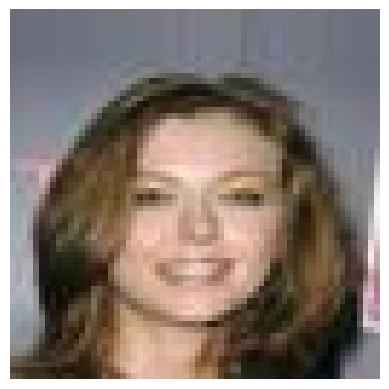

In [ ]:
import matplotlib.pyplot as plt

images = next(iter(dataloader))

img = (images[0] * 0.5) + 0.5

plt.imshow(img.permute(1,2,0))
plt.axis("off")
plt.show()


# **سوال1-3**

# **arthitecture**

In [ ]:
import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# =====================
# VAE Model
# =====================

class VAE(nn.Module):

    def __init__(self, latent_dim=128):

        super().__init__()

        self.latent_dim = latent_dim

        # ========= Encoder =========

        self.encoder = nn.Sequential(

            nn.Conv2d(3, 32, 4, 2, 1),   # 64 → 32
            nn.ReLU(),

            nn.Conv2d(32, 64, 4, 2, 1),  # 32 → 16
            nn.ReLU(),

            nn.Conv2d(64, 128, 4, 2, 1), # 16 → 8
            nn.ReLU(),

            nn.Conv2d(128, 256, 4, 2, 1), # 8 → 4
            nn.ReLU(),

            nn.Flatten()
        )


        self.fc_mu = nn.Linear(256*4*4, latent_dim)
        self.fc_logvar = nn.Linear(256*4*4, latent_dim)


        # ========= Decoder =========

        self.fc_decode = nn.Linear(latent_dim, 256*4*4)


        self.decoder = nn.Sequential(

            nn.ConvTranspose2d(256,128,4,2,1), # 4 → 8
            nn.ReLU(),

            nn.ConvTranspose2d(128,64,4,2,1), # 8 → 16
            nn.ReLU(),

            nn.ConvTranspose2d(64,32,4,2,1), # 16 → 32
            nn.ReLU(),

            nn.ConvTranspose2d(32,3,4,2,1), # 32 → 64

            nn.Tanh()
        )


    def encode(self,x):

        x = self.encoder(x)

        mu = self.fc_mu(x)
        logvar = self.fc_logvar(x)

        return mu, logvar


    def reparameterize(self,mu,logvar):

        std = torch.exp(0.5*logvar)
        eps = torch.randn_like(std)

        return mu + eps*std


    def decode(self,z):

        x = self.fc_decode(z)

        x = x.view(-1,256,4,4)

        x = self.decoder(x)

        return x


    def forward(self,x):

        mu, logvar = self.encode(x)

        z = self.reparameterize(mu,logvar)

        x_recon = self.decode(z)

        return x_recon, mu, logvar



model = VAE().to(device)

print("Model ready")


Model ready


# **Loss**

In [ ]:
def vae_loss(recon_x, x, mu, logvar):

    recon_loss = nn.functional.mse_loss(
        recon_x, x, reduction="sum"
    )

    kl_loss = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    )

    beta = 0.001

    return recon_loss + beta * kl_loss


In [ ]:
def evaluate(model, loader):

    model.eval()

    total_loss = 0

    with torch.no_grad():

        for images in loader:

            images = images.to(device)

            recon, mu, logvar = model(images)

            loss = vae_loss(recon, images, mu, logvar)

            total_loss += loss.item()

    return total_loss / len(loader.dataset)


# **train**

In [ ]:
from torch.utils.data import random_split, DataLoader

# نسبت تقسیم
train_size = int(0.8 * len(dataset))
val_size = int(0.1 * len(dataset))
test_size = len(dataset) - train_size - val_size

train_dataset, val_dataset, test_dataset = random_split(
    dataset,
    [train_size, val_size, test_size]
)

# ساخت dataloader

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)

test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)


print("Train:", len(train_dataset))
print("Val:", len(val_dataset))
print("Test:", len(test_dataset))


Train: 6400
Val: 800
Test: 800


In [ ]:
#optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=3e-4
)

epochs = 30

train_losses = []
val_losses = []
test_losses = []


for epoch in range(epochs):

    model.train()

    train_loss = 0

    for images in train_loader:

        images = images.to(device)

        optimizer.zero_grad()

        recon, mu, logvar = model(images)

        loss = vae_loss(recon, images, mu, logvar)

        loss.backward()

        optimizer.step()

        train_loss += loss.item()


    train_loss /= len(train_loader.dataset)


    val_loss = evaluate(model, val_loader)

    test_loss = evaluate(model, test_loader)


    train_losses.append(train_loss)
    val_losses.append(val_loss)
    test_losses.append(test_loss)


    print(f"""
Epoch {epoch+1}

Train Loss: {train_loss:.2f}

Val Loss: {val_loss:.2f}

Test Loss: {test_loss:.2f}
""")



Epoch 1

Train Loss: 3092.31

Val Loss: 1642.87

Test Loss: 1681.71


Epoch 2

Train Loss: 1324.33

Val Loss: 1110.94

Test Loss: 1151.63


Epoch 3

Train Loss: 1005.90

Val Loss: 933.07

Test Loss: 958.75


Epoch 4

Train Loss: 858.25

Val Loss: 802.13

Test Loss: 823.02


Epoch 5

Train Loss: 749.74

Val Loss: 722.21

Test Loss: 743.88


Epoch 6

Train Loss: 683.96

Val Loss: 677.07

Test Loss: 697.26


Epoch 7

Train Loss: 632.81

Val Loss: 645.90

Test Loss: 664.45


Epoch 8

Train Loss: 597.23

Val Loss: 597.55

Test Loss: 612.90


Epoch 9

Train Loss: 565.05

Val Loss: 574.14

Test Loss: 588.03


Epoch 10

Train Loss: 542.23

Val Loss: 568.36

Test Loss: 581.92


Epoch 11

Train Loss: 521.88

Val Loss: 537.24

Test Loss: 550.61


Epoch 12

Train Loss: 501.65

Val Loss: 520.36

Test Loss: 533.67


Epoch 13

Train Loss: 485.78

Val Loss: 511.70

Test Loss: 524.05


Epoch 14

Train Loss: 470.51

Val Loss: 495.50

Test Loss: 506.85


Epoch 15

Train Loss: 454.88

Val Loss: 482.87

T

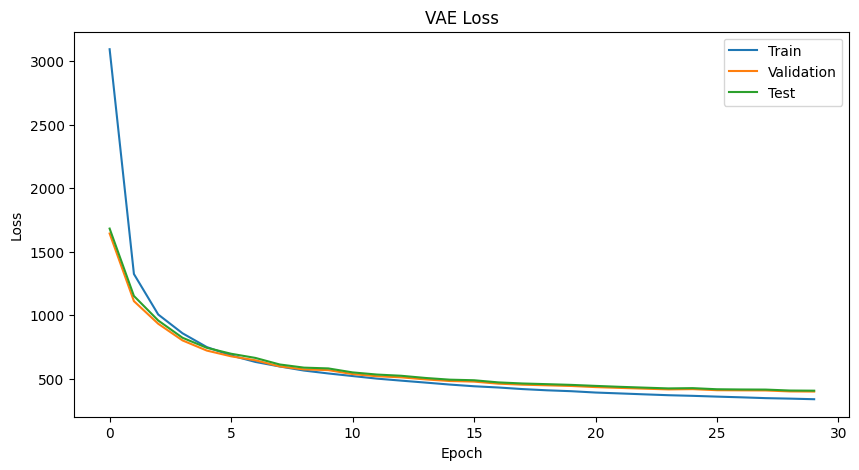

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.plot(train_losses, label="Train")

plt.plot(val_losses, label="Validation")

plt.plot(test_losses, label="Test")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title("VAE Loss")

plt.legend()

plt.show()


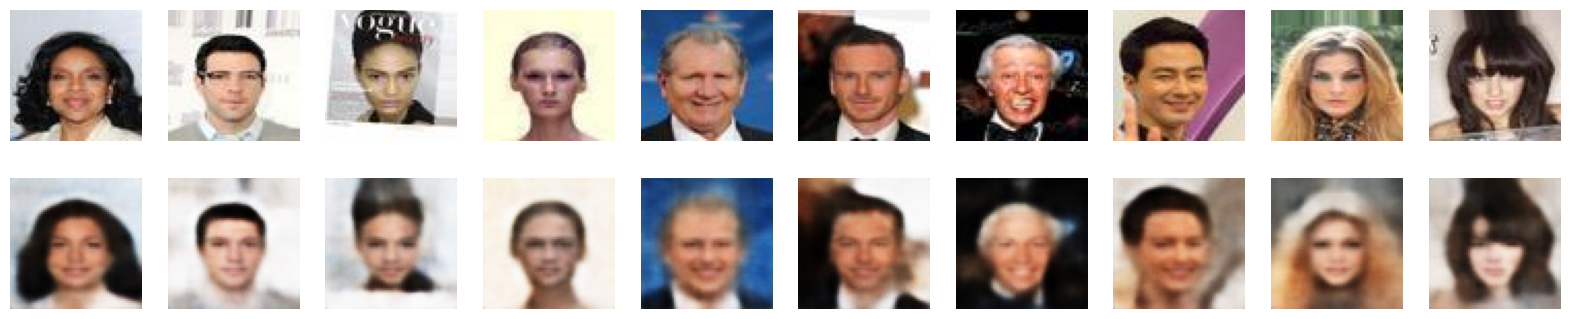

In [ ]:
model.eval()

images = next(iter(dataloader))

images = images.to(device)

with torch.no_grad():

    recon, _, _ = model(images)


images = images.cpu()
recon = recon.cpu()


# denormalize

images = images*0.5 + 0.5
recon = recon*0.5 + 0.5


plt.figure(figsize=(20,4))

for i in range(10):

    # original
    plt.subplot(2,10,i+1)
    plt.imshow(images[i].permute(1,2,0))
    plt.axis("off")

    # reconstructed
    plt.subplot(2,10,i+11)
    plt.imshow(recon[i].permute(1,2,0))
    plt.axis("off")


plt.show()


# **سوال1-4**

# **change latent space**

In [ ]:
latent_dim = 128
model = VAE(latent_dim).to(device)


In [ ]:
def train_vae(
    model,
    train_loader,
    val_loader,
    test_loader,
    optimizer,
    epochs=20
):

    train_losses = []
    val_losses = []
    test_losses = []

    for epoch in range(epochs):

        # Train

        model.train()

        train_loss = 0

        for images in train_loader:

            images = images.to(device)

            recon, mu, logvar = model(images)

            loss = vae_loss(recon, images, mu, logvar)

            optimizer.zero_grad()

            loss.backward()

            optimizer.step()

            train_loss += loss.item()


        train_loss /= len(train_loader.dataset)

        train_losses.append(train_loss)

        # Validation

        model.eval()

        val_loss = 0

        with torch.no_grad():

            for images in val_loader:

                images = images.to(device)

                recon, mu, logvar = model(images)

                loss = vae_loss(recon, images, mu, logvar)

                val_loss += loss.item()


        val_loss /= len(val_loader.dataset)

        val_losses.append(val_loss)

        # Test

        test_loss = 0

        with torch.no_grad():

            for images in test_loader:

                images = images.to(device)

                recon, mu, logvar = model(images)

                loss = vae_loss(recon, images, mu, logvar)

                test_loss += loss.item()


        test_loss /= len(test_loader.dataset)

        test_losses.append(test_loss)

        print(f"Epoch {epoch+1}/{epochs}")

        print(f"Train Loss: {train_loss:.4f}")

        print(f"Val Loss:   {val_loss:.4f}")

        print(f"Test Loss:  {test_loss:.4f}")

        print("-"*30)


    return train_losses, val_losses, test_losses


In [ ]:
def vae_loss(recon_x, x, mu, logvar):

    BCE = torch.nn.functional.mse_loss(
        recon_x,
        x,
        reduction='sum'
    )

    KLD = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    )

    return BCE + KLD


In [ ]:
latent_dims = [16, 32, 64, 128, 256]

results = {}

for latent_dim in latent_dims:

    print(f"\nTraining VAE with latent_dim = {latent_dim}")

    model = VAE(latent_dim).to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=1e-3
    )

    train_losses, val_losses, test_losses = train_vae(
        model,
        train_loader,
        val_loader,
        test_loader,
        optimizer,
        epochs=20
    )

    results[latent_dim] = {
        "train": train_losses,
        "val": val_losses,
        "test": test_losses
    }



Training VAE with latent_dim = 16
Epoch 1/20
Train Loss: 3046.2682
Val Loss:   1593.6778
Test Loss:  1635.2934
------------------------------
Epoch 2/20
Train Loss: 1349.9852
Val Loss:   1191.3216
Test Loss:  1227.1683
------------------------------
Epoch 3/20
Train Loss: 1119.7441
Val Loss:   1069.6104
Test Loss:  1099.1244
------------------------------
Epoch 4/20
Train Loss: 1037.6800
Val Loss:   1033.6471
Test Loss:  1058.1929
------------------------------
Epoch 5/20
Train Loss: 1002.2105
Val Loss:   1023.6678
Test Loss:  1044.4888
------------------------------
Epoch 6/20
Train Loss: 980.9001
Val Loss:   1003.1104
Test Loss:  1020.4700
------------------------------
Epoch 7/20
Train Loss: 964.6737
Val Loss:   1006.0253
Test Loss:  1022.0745
------------------------------
Epoch 8/20
Train Loss: 953.5675
Val Loss:   996.4757
Test Loss:  1015.4493
------------------------------
Epoch 9/20
Train Loss: 940.5357
Val Loss:   992.7820
Test Loss:  1007.8368
------------------------------

# **سوال 1-5**

# **UNET**

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class UNetVAE(nn.Module):

    def __init__(self, latent_dim=128):

        super().__init__()

        self.latent_dim = latent_dim


        # Encoder

        self.enc1 = nn.Conv2d(3, 32, 4, 2, 1)

        self.enc2 = nn.Conv2d(32, 64, 4, 2, 1)

        self.enc3 = nn.Conv2d(64, 128, 4, 2, 1)

        self.enc4 = nn.Conv2d(128, 256, 4, 2, 1)


        self.fc_mu = nn.Linear(256*4*4, latent_dim)

        self.fc_logvar = nn.Linear(256*4*4, latent_dim)


        self.fc_decode = nn.Linear(latent_dim, 256*4*4)


        # Decoder

        self.dec4 = nn.ConvTranspose2d(256,128,4,2,1)

        self.dec3 = nn.ConvTranspose2d(256,64,4,2,1)

        self.dec2 = nn.ConvTranspose2d(128,32,4,2,1)

        self.dec1 = nn.ConvTranspose2d(64,3,4,2,1)


    def reparameterize(self, mu, logvar):

        std = torch.exp(0.5*logvar)

        eps = torch.randn_like(std)

        return mu + eps*std


    def forward(self,x):

        # Encoder

        e1 = F.relu(self.enc1(x))

        e2 = F.relu(self.enc2(e1))

        e3 = F.relu(self.enc3(e2))

        e4 = F.relu(self.enc4(e3))


        flat = e4.view(-1,256*4*4)


        mu = self.fc_mu(flat)

        logvar = self.fc_logvar(flat)


        z = self.reparameterize(mu,logvar)


        d4 = self.fc_decode(z).view(-1,256,4,4)


        # Decoder + skip connections

        d3 = F.relu(self.dec4(d4))

        d3 = torch.cat([d3,e3],dim=1)


        d2 = F.relu(self.dec3(d3))

        d2 = torch.cat([d2,e2],dim=1)


        d1 = F.relu(self.dec2(d2))

        d1 = torch.cat([d1,e1],dim=1)


        out = torch.sigmoid(self.dec1(d1))


        return out, mu, logvar


In [ ]:
def loss_function(recon, x, mu, logvar):

    recon_loss = F.mse_loss(recon, x, reduction='sum')

    kl = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    )

    return recon_loss + kl


In [ ]:
model = UNetVAE(latent_dim=128).to(device)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3
)

train_losses, val_losses, test_losses = train_vae(
    model,
    train_loader,
    val_loader,
    test_loader,
    optimizer,
    epochs=30
)


Epoch 1/30
Train Loss: 3741.9246
Val Loss:   2962.1721
Test Loss:  2990.4004
------------------------------
Epoch 2/30
Train Loss: 3051.5298
Val Loss:   2884.8080
Test Loss:  2911.0430
------------------------------
Epoch 3/30
Train Loss: 3004.3241
Val Loss:   2851.9796
Test Loss:  2877.8102
------------------------------
Epoch 4/30
Train Loss: 2982.2210
Val Loss:   2836.6230
Test Loss:  2862.2118
------------------------------
Epoch 5/30
Train Loss: 2969.8108
Val Loss:   2827.9234
Test Loss:  2853.5778
------------------------------
Epoch 6/30
Train Loss: 2961.4566
Val Loss:   2819.4738
Test Loss:  2844.9572
------------------------------
Epoch 7/30
Train Loss: 2954.8349
Val Loss:   2815.4420
Test Loss:  2840.8938
------------------------------
Epoch 8/30
Train Loss: 2950.5887
Val Loss:   2809.6896
Test Loss:  2835.0599
------------------------------
Epoch 9/30
Train Loss: 2946.3654
Val Loss:   2806.7959
Test Loss:  2832.2436
------------------------------
Epoch 10/30
Train Loss: 2943

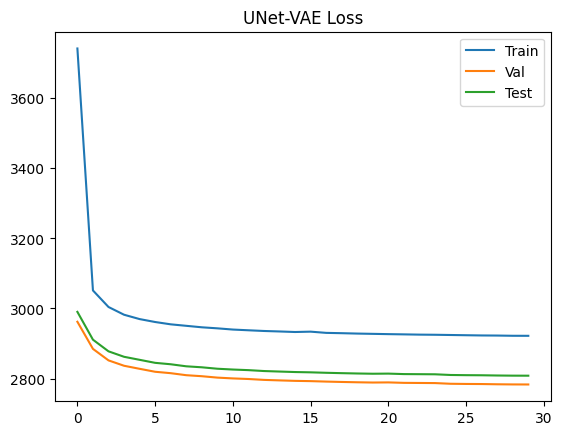

In [ ]:
plt.plot(train_losses,label="Train")

plt.plot(val_losses,label="Val")

plt.plot(test_losses,label="Test")

plt.legend()

plt.title("UNet-VAE Loss")

plt.show()
